<a href="https://colab.research.google.com/github/shakirullah-khan/snow-cover-segmentation-deep-learning/blob/main/notebooks/vision_transformers/15_SegFormer_Mit_B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook contains the complete training log and evaluation output for  SegFormer_Mit-B5 on 9,026 Sentinel-2 patches. The run was executed using Google Colab GPU resources. Cell outputs below reflect the completed experiment.

In [ ]:
# Install required libraries
!pip install -q transformers datasets evaluate accelerate webdataset albumentations

import os, shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import webdataset as wds
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import matplotlib.pyplot as plt
import random
import warnings
from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ SegFormer Environment Ready! Device: {device}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 6.9 MB/s eta 0:00:00
Mounted at /content/drive
✅ SegFormer Environment Ready! Device: cuda


In [ ]:
drive_dataset_path = "/content/drive/My Drive/Swat_Snow_Cover_Project/WebDataset/snow_patches_5000_random.tar"
colab_dataset_path = "/tmp/snow_patches_5000_random.tar"

os.makedirs(os.path.dirname(colab_dataset_path), exist_ok=True)
if not os.path.exists(colab_dataset_path):
    print("📥 Copying dataset to local /tmp...")
    shutil.copy(drive_dataset_path, colab_dataset_path)

print(f"✅ Dataset ready: {os.path.getsize(colab_dataset_path)/1024**3:.2f} GB")
wds_path = colab_dataset_path

📥 Copying dataset to local /tmp...
✅ Dataset ready: 0.41 GB


In [ ]:
MODEL_NAME = "SegFormer_MiT_B5"
final_results_path = "/content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results"
model_results_path = os.path.join(final_results_path, MODEL_NAME)

os.makedirs(model_results_path, exist_ok=True)
print(f"📁 Results Path: {model_results_path}")

📁 Results Path: /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/SegFormer_MiT_B5


In [ ]:
CONFIG = {
    "model_checkpoint": "nvidia/mit-b5",
    "num_epochs": 50,
    "batch_size": 8,
    "learning_rate": 6e-5,
    "num_workers": 0,
    "total_patches": 5000,
    "img_size": 256
}

CONFIG["train_size"] = int(CONFIG["total_patches"] * 0.7)
CONFIG["val_size"] = int(CONFIG["total_patches"] * 0.2)
CONFIG["test_size"] = CONFIG["total_patches"] - CONFIG["train_size"] - CONFIG["val_size"]

train_batches = CONFIG["train_size"] // CONFIG["batch_size"]
val_batches = CONFIG["val_size"] // CONFIG["batch_size"]

In [ ]:
# Initialize the HuggingFace processor to get MiT-B5 specific normalization
processor = SegformerImageProcessor.from_pretrained(CONFIG["model_checkpoint"])

train_transform = A.Compose([
    A.Resize(CONFIG["img_size"], CONFIG["img_size"]),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Normalize(mean=processor.image_mean, std=processor.image_std),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(CONFIG["img_size"], CONFIG["img_size"]),
    A.Normalize(mean=processor.image_mean, std=processor.image_std),
    ToTensorV2(),
])

def preprocess_sample(sample, transform):
    img = np.array(sample["image.png"].convert("RGB"))
    msk = np.array(sample["mask.png"].convert("L")) / 255.0
    t = transform(image=img, mask=msk)
    # SegFormer expects long labels for the cross-entropy loss
    return t["image"], t["mask"].squeeze(0).long()

preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

In [ ]:
train_dataset = (wds.WebDataset(wds_path)
    .shuffle(1000).decode("pil").to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, train_transform))
    .batched(CONFIG["batch_size"]))

val_dataset = (wds.WebDataset(wds_path)
    .decode("pil").to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, val_transform))
    .batched(CONFIG["batch_size"]))

train_loader = wds.WebLoader(train_dataset, batch_size=None).with_epoch(train_batches)
val_loader = wds.WebLoader(val_dataset, batch_size=None).with_epoch(val_batches)

print("✅ Data loaders ready!")

✅ Data loaders ready!


In [ ]:
# Load SegFormer with MiT-B5 backbone and 2 output classes (background/snow)
model = SegformerForSemanticSegmentation.from_pretrained(
    CONFIG["model_checkpoint"],
    num_labels=2,
    ignore_mismatched_sizes=True
).to(device)

print(f"✅ SegFormer MiT-B5 Built! Params: {model.num_parameters():,}")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/328M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/328M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/1156 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b5
Key                                           | Status     | 
----------------------------------------------+------------+-
classifier.bias                               | UNEXPECTED | 
classifier.weight                             | UNEXPECTED | 
decode_head.linear_c.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_var            | MISSING    | 
decode_head.classifier.weight                 | MISSING    | 
decode_head.batch_norm.running_mean           | MISSING    | 
decode_head.batch_norm.num_batches_tracked    | MISSING    | 
decode_head.linear_fuse.weight                | MISSING    | 
decode_head.batch_norm.bias                   | MISSING    | 
decode_head.classifier.bias                   | MISSING    | 
decode_head.batch_norm.weight                 | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different ta

✅ SegFormer MiT-B5 Built! Params: 84,594,882


In [ ]:
def calc_metrics(pred, target):
    # Upsample prediction to match target size (256x256)
    pred_upsampled = F.interpolate(pred, size=target.shape[-2:], mode="bilinear", align_corners=False)
    pred_labels = pred_upsampled.argmax(dim=1)

    inter = (pred_labels * target).sum()
    union = pred_labels.sum() + target.sum() - inter
    dice = (2 * inter + 1e-6) / (pred_labels.sum() + target.sum() + 1e-6)
    iou = (inter + 1e-6) / (union + 1e-6)
    return iou, dice

optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["learning_rate"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["num_epochs"])

history = {k: [] for k in ["train_loss", "val_loss", "train_iou", "val_iou", "train_dice", "val_dice", "learning_rate"]}
best_dice = 0.0

In [ ]:
def train_epoch(model, loader, num_batches):
    model.train()
    m = {"loss": [], "iou": [], "dice": []}
    pbar = tqdm(enumerate(loader), total=num_batches, desc="Train")
    for bi, (imgs, msks) in pbar:
        if bi >= num_batches: break
        imgs, msks = imgs.to(device), msks.to(device)

        optimizer.zero_grad()
        outputs = model(pixel_values=imgs, labels=msks)
        loss = outputs.loss
        loss.backward()
        optimizer.step()

        iou, dice = calc_metrics(outputs.logits, msks)
        m["loss"].append(loss.item())
        m["iou"].append(iou.item()); m["dice"].append(dice.item())
        pbar.set_postfix(loss=f"{np.mean(m['loss']):.4f}", dice=f"{np.mean(m['dice']):.4f}")
    return {k: np.mean(v) for k, v in m.items()}

def val_epoch(model, loader, num_batches):
    model.eval()
    m = {"loss": [], "iou": [], "dice": []}
    with torch.no_grad():
        for bi, (imgs, msks) in enumerate(loader):
            if bi >= num_batches: break
            imgs, msks = imgs.to(device), msks.to(device)
            outputs = model(pixel_values=imgs, labels=msks)

            iou, dice = calc_metrics(outputs.logits, msks)
            m["loss"].append(outputs.loss.item())
            m["iou"].append(iou.item()); m["dice"].append(dice.item())
    return {k: np.mean(v) for k, v in m.items()}

In [ ]:
print("🚀 TRAINING START")
for epoch in range(CONFIG["num_epochs"]):
    print(f"\nEpoch {epoch+1}/{CONFIG['num_epochs']}")
    train_m = train_epoch(model, train_loader, train_batches)
    val_m = val_epoch(model, val_loader, val_batches)

    scheduler.step()
    lr = optimizer.param_groups[0]["lr"]

    for k in train_m.keys():
        history[f"train_{k}"].append(train_m[k])
        history[f"val_{k}"].append(val_m[k])
    history["learning_rate"].append(lr)

    if val_m["dice"] > best_dice:
        best_dice = val_m["dice"]
        torch.save(model.state_dict(), os.path.join(model_results_path, "best_model.pth"))
        print(f"  ⭐ NEW BEST VAL DICE: {best_dice:.4f}")

🚀 TRAINING START

Epoch 1/50


Train: 100%|██████████| 437/437 [05:12<00:00,  1.40it/s, dice=0.8973, loss=0.1615]


  ⭐ NEW BEST VAL DICE: 0.8920

Epoch 2/50


Train: 100%|██████████| 437/437 [05:03<00:00,  1.44it/s, dice=0.9210, loss=0.1186]


  ⭐ NEW BEST VAL DICE: 0.9251

Epoch 3/50


Train: 100%|██████████| 437/437 [05:04<00:00,  1.44it/s, dice=0.9257, loss=0.1096]


... (90 outputs left out)


Epoch 49/50


Train: 100%|██████████| 437/437 [05:02<00:00,  1.44it/s, dice=0.9428, loss=0.0812]


  ⭐ NEW BEST VAL DICE: 0.9433

Epoch 50/50


Train: 100%|██████████| 437/437 [05:03<00:00,  1.44it/s, dice=0.9428, loss=0.0814]


In [ ]:
torch.save(model.state_dict(), os.path.join(model_results_path, "final_model.pth"))
pd.DataFrame(history).to_csv(os.path.join(model_results_path, "training_history.csv"), index=False)
print(f"✅ SAVED TO: {model_results_path}")

✅ SAVED TO: /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/SegFormer_MiT_B5


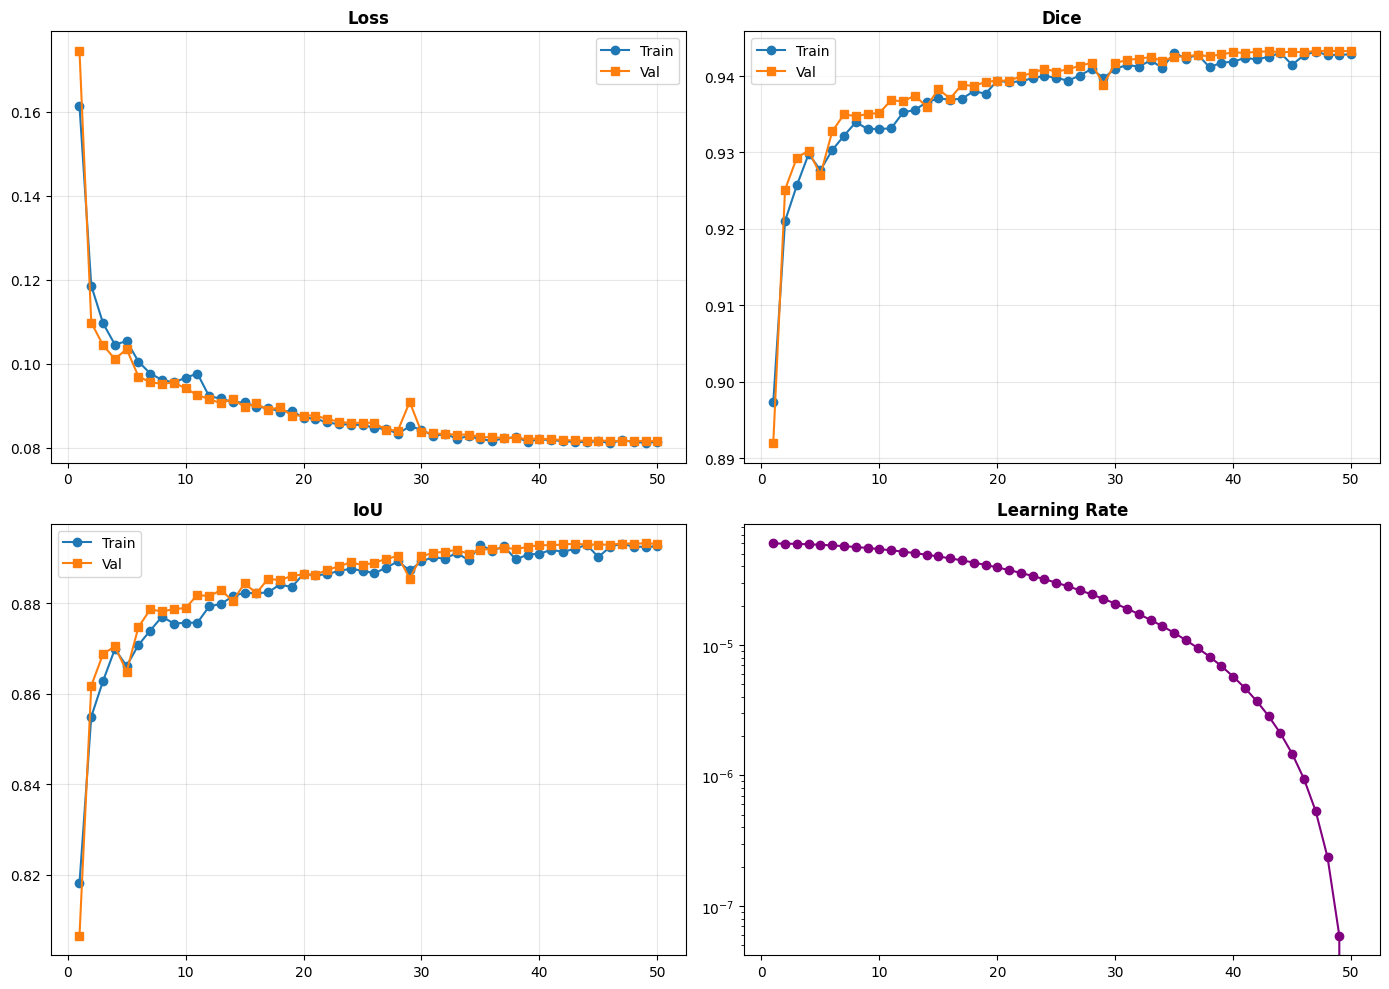

In [ ]:
epochs_range = np.arange(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, (m, title) in enumerate([("loss", "Loss"), ("dice", "Dice"), ("iou", "IoU")]):
    row, col = divmod(i, 2)
    axes[row, col].plot(epochs_range, history[f"train_{m}"], "o-", label="Train")
    axes[row, col].plot(epochs_range, history[f"val_{m}"], "s-", label="Val")
    axes[row, col].set_title(title, fontweight="bold")
    axes[row, col].legend(); axes[row, col].grid(alpha=0.3)

axes[1, 1].plot(epochs_range, history["learning_rate"], "o-", color="purple")
axes[1, 1].set_title("Learning Rate", fontweight="bold"); axes[1, 1].set_yscale("log")

plt.tight_layout()
plt.savefig(os.path.join(model_results_path, "training_curves.png"), dpi=300)
plt.show()